# M02 gravedad de prismas: operador de producción y oráculo independiente

**Pregunta:** En un perfil exterior, ¿con qué precisión reproduce el operador SimPEG/Geoana del producto la gravedad vertical analítica de Choclo para el mismo prisma de 1000 kg/m³?

**Nivel 3 · Prerrequisitos: la lección previa de fundamentos; lectura estimada: 60 minutos.**

## Objetivos

Validar un cálculo directo acotado frente a Choclo y probar linealidad de densidad y efecto de distancia receptora.

## Preparación

Use el entorno Python 3.12 fijado. Créelo desde la raíz con `scripts/setup.ps1 -Notebooks` en Windows o `scripts/setup.sh --notebooks` en Linux/macOS. El comando se documenta como referencia; el notebook no instala paquetes.

```text
pip install simpeg==0.25.2 geoana==0.8.1 choclo==0.3.2
```

Importar una vez el método y herramientas gráficas. La celda informa implementación activa.

In [1]:
# Importar métodos del repositorio y herramientas gráficas.
from importlib.metadata import version
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
import gravity_forward
print('Motor:', gravity_forward.ENGINE)
import choclo
from importlib.metadata import version
print('Choclo:', version('choclo'))


Motor: simpeg-0.25.2-geoana-0.8.1-f64-ram
Choclo: 0.3.2


## Datos

El notebook construye un prisma de una celda con x,y=[−50,50] m y z=[−100,0] m, densidad 1000 kg/m³ y 81 receptores a z=100 m. Es control sintético propio, no dato de campo. Producción usa `data-pipeline/gravity_forward.py`, SimPEG 0.25.2 y Geoana 0.8.1. La comparación analítica independiente usa Choclo 0.3.2 con mismos límites, densidad y receptores. Los documentos de diseño y validación conservan procedencia del contrato.

Leer entradas declaradas o construir geometría sintética propia. No se carga salida de solver.

In [2]:
# Construir prisma de una celda y perfil exterior simétrico.
mesh = {'origin_m': np.array([-50., -50., -100.]), 'hx_m': np.array([100.]),
        'hy_m': np.array([100.]), 'hz_m': np.array([100.]),
        'active': np.array([True])}
x = np.linspace(-400., 400., 81)
receivers = np.column_stack([x, np.zeros_like(x), np.full_like(x, 100.)])
base = {'schema': 'gravity-prism-forward-request-1',
        'frame': dict(gravity_forward.FRAME), 'mesh': mesh,
        'receivers_m': receivers, 'engine': gravity_forward.ENGINE}
prism_bounds = (-50., 50., -50., 50., -100., 0.)
sparse_receivers = receivers[::10]
offset_receivers = receivers + np.array([0., 150., 0.])
fine_x = np.linspace(-400., 400., 161)
fine_receivers = np.column_stack([fine_x, np.zeros(161), np.full(161, 100.)])
print('Receptores:', len(receivers), '| densidad: 1000 kg/m3')


Receptores: 81 | densidad: 1000 kg/m3


## Método

### Convención física e integral

Para contraste Δρ en volumen V, aceleración hacia arriba es g_z(r)=G∫_V Δρ(z′−z)/|r−r′|³ dV. Sobre masa enterrada positiva, g_z es negativo bajo convención hacia arriba. El producto devuelve mGal; el resultado SI de Choclo se multiplica por 10⁵. Coordenadas y límites deben coincidir o describen experimentos distintos.

### Ejecutar el motor del producto

La solicitud fija ejes locales este, norte, arriba; metros; TensorMesh de una celda; celda activa; densidad física y receptores exteriores. El wrapper valida versiones, nodos y límites reales, volúmenes físicos, separación y arreglos de salida. Estos controles aportan reproducibilidad más allá de evaluar una fórmula.

### Cambiar muestreo y conservar la fuente

Una llamada con pocos receptores comprueba signo y escala; otra densa resuelve la misma fuente sobre el perfil. Solo cambian posiciones receptoras. El perfil debe ser simétrico respecto de x=0 porque prisma y línea son simétricos. Es invariante físico a revisar, no observación ajustada.

### Probar dos invariantes físicos

Un cálculo duplica densidad sin cambiar geometría. Gravedad newtoniana es lineal en densidad, por lo que aceleración debe duplicarse salvo error de punto flotante. Otra llamada desplaza la línea 150 m al norte y mide cambio con distancia. Cada llamada cambia una causa controlada y produce arreglos reales del solver.

### Comparar un método independiente

Choclo calcula campo analítico de prisma independientemente de la ruta SimPEG/Geoana del producto. Recibe límites, densidad y receptores idénticos. El notebook calcula diferencias con signo y error absoluto máximo. El acuerdo es validación cruzada de este problema directo acotado, no prueba de una inversión correcta.

### Alcance del estado del arte

SimPEG es un marco extendido de simulación e inversión; Choclo provee geometrías analíticas de campos potenciales. La comparación es justa porque ambos calculan la misma magnitud con convenciones explícitas. No es benchmark, convergencia general de malla, experimento geológico incierto, evaluación de procesamiento ni selección inversa.

### Separar el límite de inversión

Un oráculo directo no establece recuperación de densidad. Invertir agrega adquisición finita, ruido, regularización, cotas, malla y no unicidad. Los dossiers L2 y geométricos del producto tienen alcance propio; esta comparación limpia no los reemplaza. Consulte la validación enlazada antes de afirmar aceptación de solver o uso de campo.

Ejecutar operador de producción fijado; establece perfil y jacobiano.

In [3]:
# Evalúe el método directo de producción del producto.
production_result_request = {**base, 'density_kg_m3': np.array([1000.])}
production_result = gravity_forward.forward_gravity(production_result_request)
centre = len(production_result['gz_up_mgal']) // 2
print('resultado_producción gz central:', float(production_result['gz_up_mgal'][centre]), 'mGal')

resultado_producción gz central: -0.2927236040238318 mGal


Muestrear misma fuente en nueve estaciones. Solo cambia muestreo receptor.

In [4]:
# Evalúe el método directo del producto con muestreo disperso.
sparse_result_request = {**base, 'receivers_m': sparse_receivers, 'density_kg_m3': np.array([1000.])}
sparse_result = gravity_forward.forward_gravity(sparse_result_request)
centre = len(sparse_result['gz_up_mgal']) // 2
print('resultado_dispersa gz central:', float(sparse_result['gz_up_mgal'][centre]), 'mGal')

resultado_dispersa gz central: -0.2927236040238318 mGal


Duplicar densidad con geometría y receptores fijos; gravedad newtoniana predice factor dos.

In [5]:
# Evalúe el método directo del producto con densidad duplicada.
double_result_request = {**base, 'density_kg_m3': np.array([2000.])}
double_result = gravity_forward.forward_gravity(double_result_request)
centre = len(double_result['gz_up_mgal']) // 2
print('resultado_doble gz central:', float(double_result['gz_up_mgal'][centre]), 'mGal')

resultado_doble gz central: -0.5854472080476636 mGal


Desplazar perfil 150 m al norte para medir sensibilidad lateral.

In [6]:
# Evalúe el método directo del producto con perfil desplazado.
offset_result_request = {**base, 'receivers_m': offset_receivers, 'density_kg_m3': np.array([1000.])}
offset_result = gravity_forward.forward_gravity(offset_result_request)
centre = len(offset_result['gz_up_mgal']) // 2
print('resultado_desplazado gz central:', float(offset_result['gz_up_mgal'][centre]), 'mGal')

resultado_desplazado gz central: -0.10495285561200406 mGal


Reevaluar línea de 161 estaciones con llamada nueva al solver.

In [7]:
# Evalúe el método directo del producto con muestreo fino.
fine_result_request = {**base, 'receivers_m': fine_receivers, 'density_kg_m3': np.array([1000.])}
fine_result = gravity_forward.forward_gravity(fine_result_request)
centre = len(fine_result['gz_up_mgal']) // 2
print('resultado_fino gz central:', float(fine_result['gz_up_mgal'][centre]), 'mGal')

resultado_fino gz central: -0.2927236040238318 mGal


## Estado del arte

Alcance del estado del arte

SimPEG es un marco extendido de simulación e inversión; Choclo provee geometrías analíticas de campos potenciales. La comparación es justa porque ambos calculan la misma magnitud con convenciones explícitas. No es benchmark, convergencia general de malla, experimento geológico incierto, evaluación de procesamiento ni selección inversa.

Llamar fórmula analítica de prisma de Choclo con mismos límites, densidad y receptores. Convertir aceleración SI a mGal.

In [8]:
# Calcule el oráculo analítico independiente con las mismas entradas físicas.
oracle = np.array([choclo.prism.gravity_u(*receiver, *prism_bounds, 1000.) * 1e5
                   for receiver in receivers])
product = production_result['gz_up_mgal']
difference = product - oracle
max_error = float(np.max(np.abs(difference)))
print({'max_abs_difference_mgal': max_error,
       'product_centre_mgal': float(product[len(x) // 2]),
       'oracle_centre_mgal': float(oracle[len(x) // 2])})

{'max_abs_difference_mgal': 7.587680483922554e-15, 'product_centre_mgal': -0.2927236040238318, 'oracle_centre_mgal': -0.29272360402383146}


Comparar solución de producción y Choclo; el panel residual usa escala separada.

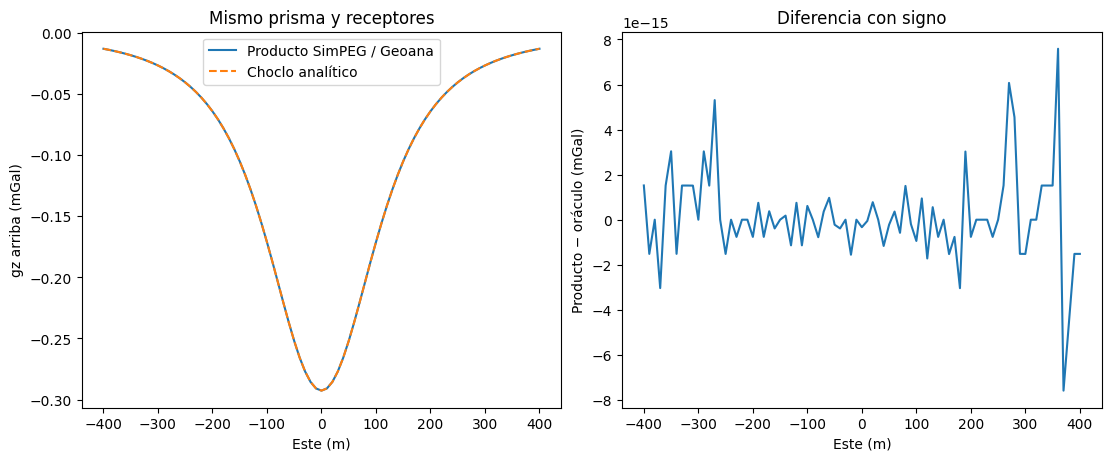

In [9]:
# Graficar predicciones de producción y analítica más diferencia con signo.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax.plot(x, product, label='Producto SimPEG / Geoana')
ax.plot(x, oracle, '--', label='Choclo analítico')
bx.plot(x, difference)
ax.set(xlabel='Este (m)', ylabel='gz arriba (mGal)', title='Mismo prisma y receptores')
bx.set(xlabel='Este (m)', ylabel='Producto − oráculo (mGal)', title='Diferencia con signo')
ax.legend()
plt.show()

El panel superior superpone predicción de producción y oráculo analítico de Choclo en receptores exteriores idénticos; el inferior grafica producto menos oráculo en mGal. Se ven simetría y concordancia, mientras la escala residual revela diferencias ocultas en el eje principal. Es un prisma y densidad, no ajuste inverso ni comparación de campo.

Probar escala de densidad y respuesta desplazada. Son invariantes y sensibilidad física, no alternativas visuales.

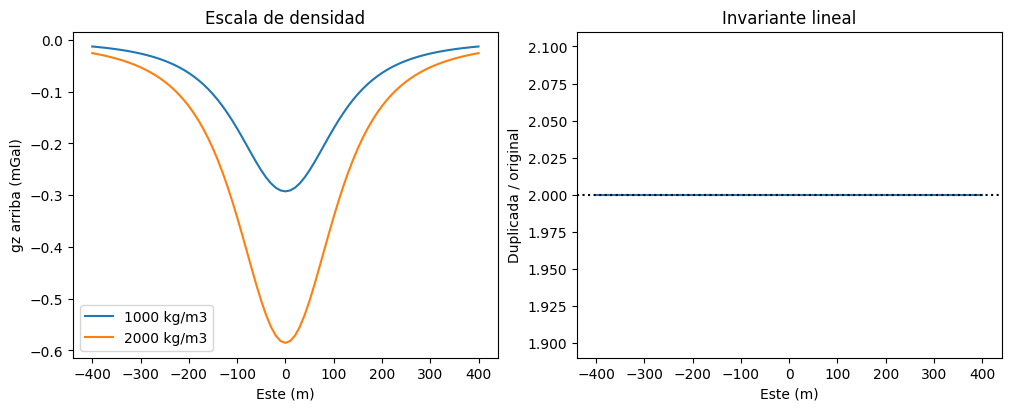

{'error_razon_maximo': 0.0, 'n_linea_densa': 161, 'centro_desplazado_mgal': -0.10495285561200406}


In [10]:
# Cuantificar linealidad y graficar sensibilidad a distancia.
ratio = double_result['gz_up_mgal'] / production_result['gz_up_mgal']
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax.plot(x, product, label='1000 kg/m3')
ax.plot(x, double_result['gz_up_mgal'], label='2000 kg/m3')
bx.plot(x, ratio)
bx.axhline(2.0, color='black', linestyle=':')
ax.set(xlabel='Este (m)', ylabel='gz arriba (mGal)', title='Escala de densidad')
bx.set(xlabel='Este (m)', ylabel='Duplicada / original', title='Invariante lineal')
ax.legend()
plt.show()
ratio_error = float(np.max(np.abs(ratio - 2.0)))
print({'error_razon_maximo': ratio_error, 'n_linea_densa': len(fine_result['gz_up_mgal']),
       'centro_desplazado_mgal': float(offset_result['gz_up_mgal'][len(x) // 2])})

La segunda figura prueba escala con densidad duplicada y muestra perfil desplazado lateralmente. Cuantifica linealidad de amplitud y hace visible sensibilidad a distancia. Estos controles corresponden a una malla y fuente. No demuestran convergencia general, calibración de errores, estabilidad inversa ni precisión universal.

### Límites de comparación

Separar el límite de inversión

Un oráculo directo no establece recuperación de densidad. Invertir agrega adquisición finita, ruido, regularización, cotas, malla y no unicidad. Los dossiers L2 y geométricos del producto tienen alcance propio; esta comparación limpia no los reemplaza. Consulte la validación enlazada antes de afirmar aceptación de solver o uso de campo. La discrepancia se informa en mGal.

## Resultados

**Respuesta:** La diferencia máxima producto–Choclo es 7.587680483922554e-15 mGal y el error de razón con densidad duplicada es 0.0. Son controles directos acotados.

In [11]:
# Informar evidencia entre motores e invariante físico calculada.
print({'error_absoluto_maximo_mgal': max_error,
       'centro_producto_mgal': float(product[len(x) // 2]),
       'centro_choclo_mgal': float(oracle[len(x) // 2]),
       'error_razon_densidad': ratio_error})

{'error_absoluto_maximo_mgal': 7.587680483922554e-15, 'centro_producto_mgal': -0.2927236040238318, 'centro_choclo_mgal': -0.29272360402383146, 'error_razon_densidad': 0.0}


## Resumen

La respuesta directa del producto se contrasta con un prisma analítico independiente y entradas idénticas. El acuerdo respalda este caso y contrato de signo/unidades. No certifica inversión, elegibilidad de datos de campo, solver para una matriz de levantamiento ni interpretación geológica.

## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015
- https://www.fatiando.org/choclo/latest/